<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/03_schwarzschild_geodesics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import sys

repo_path = "/content/Blackhole_simulator_rayTracing"

if not os.path.exists(repo_path):
    %cd /content
    !git clone https://github.com/AnshG-19/Blackhole_simulator_rayTracing.git

os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("Repository connected:", os.getcwd())

/content
Cloning into 'Blackhole_simulator_rayTracing'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 92 (delta 31), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 2.86 MiB | 13.43 MiB/s, done.
Resolving deltas: 100% (31/31), done.
Repository connected: /content/Blackhole_simulator_rayTracing


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

M = 1.0  # Geometric units: G = c = 1

r_s = 2 * M
r_ph = 3 * M
r_isco = 6 * M

print(f"Event horizon: {r_s:.1f} M")
print(f"Photon sphere: {r_ph:.1f} M")
print(f"ISCO: {r_isco:.1f} M")

Event horizon: 2.0 M
Photon sphere: 3.0 M
ISCO: 6.0 M


In [ ]:
def schwarzschild_geodesic(tau, state, E, L, M=1.0):
    """
    Timelike geodesic equations in Schwarzschild spacetime.

    state = [r, dr/dtau, phi]
    """
    r, radial_velocity, phi = state

    if r <= 2 * M:
        raise ValueError("The trajectory reached the event horizon.")

    f = 1 - (2 * M / r)

    d2r_dtau2 = (
        -M / r**2
        + L**2 / r**3
        - 3 * M * L**2 / r**4
    )

    dphi_dtau = L / r**2

    return [radial_velocity, d2r_dtau2, dphi_dtau]

print("Geodesic equations defined.")

Geodesic equations defined.


In [ ]:
def circular_orbit_parameters(radius, M=1.0):
    """Return specific energy and angular momentum for a circular orbit."""
    r = float(radius)

    if r <= 3 * M:
        raise ValueError("A timelike circular orbit requires r > 3M.")

    energy = np.sqrt((r - 2 * M)**2 / (r * (r - 3 * M)))
    angular_momentum = np.sqrt(M * r**2 / (r - 3 * M))

    return energy, angular_momentum


for radius in [4, 6, 8, 10]:
    energy, angular_momentum = circular_orbit_parameters(radius, M)
    stability = "stable" if radius >= 6 * M else "unstable"
    print(
        f"r = {radius:2d} M | E = {energy:.4f} | "
        f"L = {angular_momentum:.4f} | {stability}"
    )

r =  4 M | E = 1.0000 | L = 4.0000 | unstable
r =  6 M | E = 0.9428 | L = 3.4641 | stable
r =  8 M | E = 0.9487 | L = 3.5777 | stable
r = 10 M | E = 0.9562 | L = 3.7796 | stable


In [9]:

# Choose a stable circular orbit radius
r0 = 8.0 * M

# Get angular momentum for the circular orbit at r0
_, L = circular_orbit_parameters(r0, M)

# Introduce a small outward radial velocity
initial_radial_velocity = 0.02

# Schwarzschild metric factor
f0 = 1 - 2 * M / r0

# Calculate energy consistent with the chosen initial velocity
E = np.sqrt(
    f0 * (
        1
        + L**2 / r0**2
        + initial_radial_velocity**2 / f0
    )
)

initial_state = [r0, initial_radial_velocity, 0.0]

proper_time = (0.0, 200.0)
time_points = np.linspace(*proper_time, 5000)

solution = solve_ivp(
    schwarzschild_geodesic,
    proper_time,
    initial_state,
    t_eval=time_points,
    args=(E, L, M),
    rtol=1e-9,
    atol=1e-11,
)

if not solution.success:
    raise RuntimeError(solution.message)

r = solution.y[0]
radial_velocity = solution.y[1]
phi = solution.y[2]

print("Integration successful:", solution.success)
print(f"Consistent specific energy: {E:.6f}")
print(f"Minimum radius: {r.min():.4f} M")
print(f"Maximum radius: {r.max():.4f} M")
print(f"Final orbital angle: {phi[-1]:.4f} radians")


Integration successful: True
Consistent specific energy: 0.948894
Minimum radius: 7.3128 M
Maximum radius: 8.7512 M
Final orbital angle: 11.0821 radians


In [10]:

f = 1 - 2 * M / r

energy_along_orbit = np.sqrt(
    f * (1 + L**2 / r**2)
    + radial_velocity**2
)

energy_error = np.max(np.abs(energy_along_orbit - E))

print(f"Initial energy: {E:.8f}")
print(f"Maximum energy deviation: {energy_error:.3e}")

assert energy_error < 1e-6, "Energy conservation check failed."
print("Energy conservation check passed.")


Initial energy: 0.94889409
Maximum energy deviation: 2.257e-12
Energy conservation check passed.


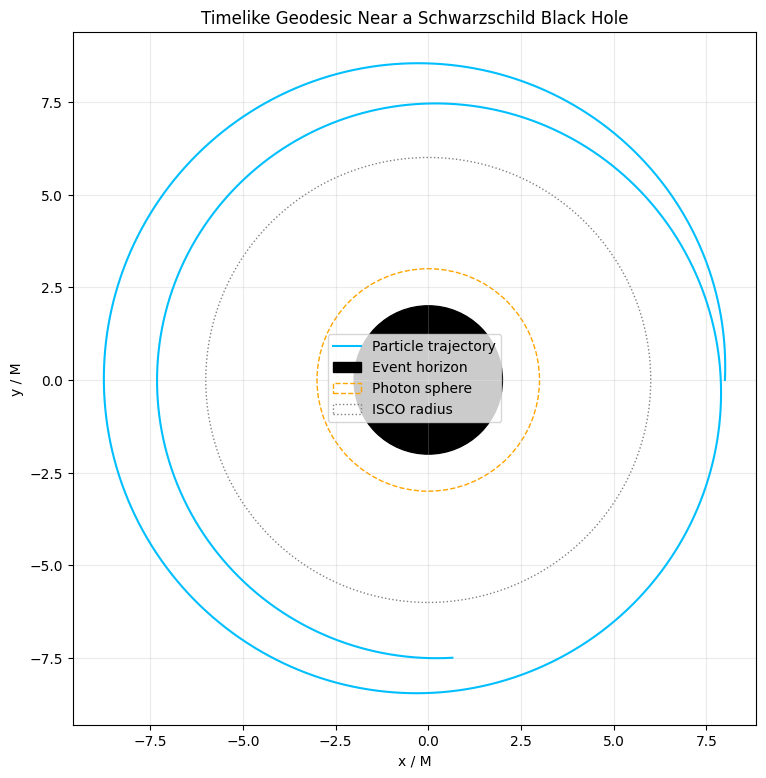

In [ ]:
x = r * np.cos(phi)
y = r * np.sin(phi)

fig, ax = plt.subplots(figsize=(9, 9))

ax.plot(x, y, color="deepskyblue", linewidth=1.5,
        label="Particle trajectory")

ax.add_patch(plt.Circle((0, 0), 2 * M, color="black",
                        label="Event horizon"))
ax.add_patch(plt.Circle((0, 0), 3 * M, fill=False,
                        color="orange", linestyle="--",
                        label="Photon sphere"))
ax.add_patch(plt.Circle((0, 0), 6 * M, fill=False,
                        color="gray", linestyle=":",
                        label="ISCO radius"))

ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Timelike Geodesic Near a Schwarzschild Black Hole")
ax.set_aspect("equal")
ax.grid(alpha=0.25)
ax.legend()

plt.show()

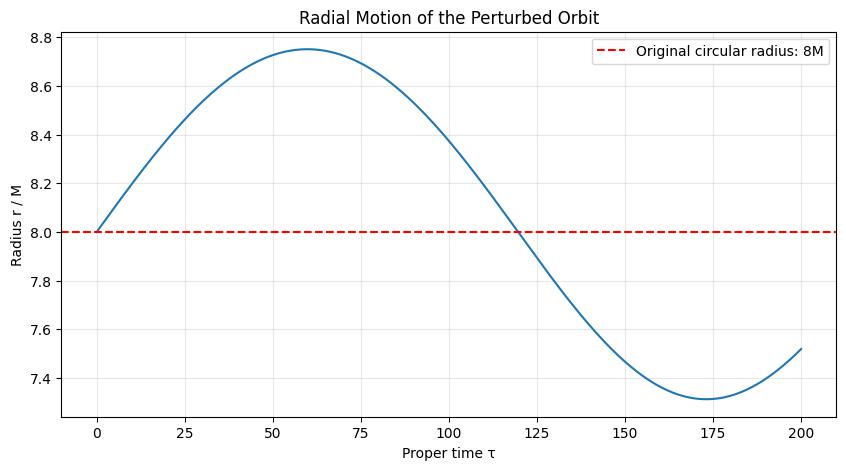

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(time_points, r, linewidth=1.5)
ax.axhline(r0, color="red", linestyle="--",
           label="Original circular radius: 8M")

ax.set_xlabel("Proper time τ")
ax.set_ylabel("Radius r / M")
ax.set_title("Radial Motion of the Perturbed Orbit")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

In [ ]:
print(f"Initial radius: {r0:.4f} M")
print(f"Minimum radius: {r.min():.4f} M")
print(f"Maximum radius: {r.max():.4f} M")
print(f"Radial variation: {r.max() - r.min():.4f} M")

assert np.all(r > 2 * M), "Trajectory crossed the event horizon."
assert np.all(np.isfinite(r)), "Non-finite radius values detected."

print("Radius checks passed.")

Initial radius: 8.0000 M
Minimum radius: 7.3128 M
Maximum radius: 8.7512 M
Radial variation: 1.4383 M
Radius checks passed.


# Schwarzschild Geodesics — Summary

This notebook investigates the motion of massive test particles around a non-rotating Schwarzschild black hole using geometric units, \(G=c=1\).

### Concepts demonstrated

- **Event horizon:** \(r=2M\).
- **Photon sphere:** \(r=3M\), where circular photon orbits are possible.
- **Innermost stable circular orbit (ISCO):** \(r=6M\) for massive particles.
- **Conserved quantities:** specific energy \(E\) and specific angular momentum \(L\).
- **Radial perturbations:** a small initial radial velocity produces oscillatory radial motion around a stable circular orbit.

### Numerical method

The radial equation is integrated with SciPy's `solve_ivp` using the Schwarzschild timelike geodesic equations.

### Physical interpretation

Stable circular orbits at radii greater than \(6M\) can support small radial oscillations. Circular orbits between \(3M\) and \(6M\) are unstable, while stable circular orbits do not exist below \(6M\).

**Limitation:** This simulation models test-particle motion. It does not include gravitational radiation, gas pressure, or accretion-disk hydrodynamics.


# Black Hole Simulator — Schwarzschild Geodesics

## Objectives
- Understand the path of light in Schwarzschild spacetime
- Compare captured and escaping light rays
- Explore the critical impact parameter
- Visualize several trajectories


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.patches import Circle
# from scipy.integrate import solve_ivp

# print("Schwarzschild geodesics notebook initialized.")

Schwarzschild geodesics notebook initialized.


Define the black hole
We'll use geometric units, \(G=c=M=1\).

In [ ]:
# M = 1.0

# r_s = 2 * M
# r_ph = 3 * M
# b_critical = 3 * np.sqrt(3) * M

# print("Event horizon radius:", r_s)
# print("Photon sphere radius:", r_ph)
# print("Critical impact parameter:", b_critical)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Critical impact parameter: 5.196152422706632


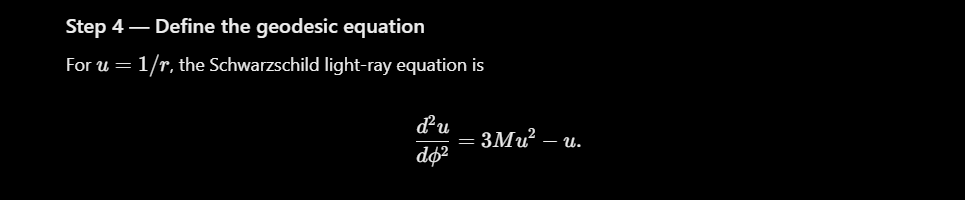

In [ ]:
# def light_ray_equations(phi, state):
#     u, v = state

#     du_dphi = v
#     dv_dphi = 3 * M * u**2 - u

#     return [du_dphi, dv_dphi]

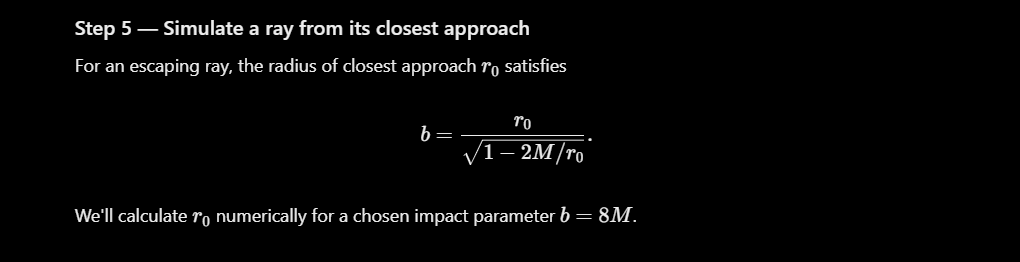

In [ ]:
# from scipy.optimize import brentq

# b = 8.0

# def closest_approach_equation(r):
#     return r**3 - b**2 * r + 2 * M * b**2

# r_min = brentq(
#     closest_approach_equation,
#     r_ph + 1e-6,
#     b
# )

# print("Impact parameter:", b)
# print("Closest approach:", r_min)

Impact parameter: 8.0
Closest approach: 6.700523482266461


Integrate the outgoing ray
At closest approach, \(du/d\phi=0\). We'll start there and integrate outward.

In [ ]:
# def escaped_ray(b, angle_end=2.5):
#     def closest_equation(r):
#         return r**3 - b**2 * r + 2 * M * b**2

#     r0 = brentq(closest_equation, r_ph + 1e-6, b)

#     initial_state = [1 / r0, 0.0]
#     angles = np.linspace(0, angle_end, 1200)

#     solution = solve_ivp(
#         light_ray_equations,
#         (0, angle_end),
#         initial_state,
#         t_eval=angles,
#         rtol=1e-9,
#         atol=1e-11
#     )

#     radii = 1 / solution.y[0]

#     return angles, radii

Plot the trajectory

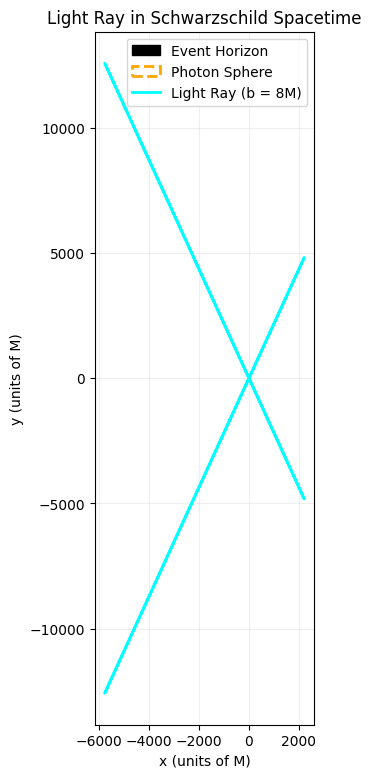

In [ ]:
# angles, radii = escaped_ray(8.0)

# # Reflect around the point of closest approach
# angles_full = np.concatenate((-angles[:0:-1], angles))
# radii_full = np.concatenate((radii[:0:-1], radii))

# x = radii_full * np.cos(angles_full)
# y = radii_full * np.sin(angles_full)

# fig, ax = plt.subplots(figsize=(9, 9))

# ax.add_patch(Circle((0, 0), r_s, color="black",
#                     label="Event Horizon"))

# ax.add_patch(Circle((0, 0), r_ph, fill=False,
#                     linestyle="--", color="orange",
#                     linewidth=2, label="Photon Sphere"))

# ax.plot(x, y, color="cyan", linewidth=2,
#         label="Light Ray (b = 8M)")

# ax.set_aspect("equal")
# ax.set_xlabel("x (units of M)")
# ax.set_ylabel("y (units of M)")
# ax.set_title("Light Ray in Schwarzschild Spacetime")
# ax.grid(alpha=0.2)
# ax.legend()

# plt.show()

Compare different impact parameters
Now we'll plot several escaping rays. Larger impact parameters generally mean the light passes farther from the black hole and bends less.

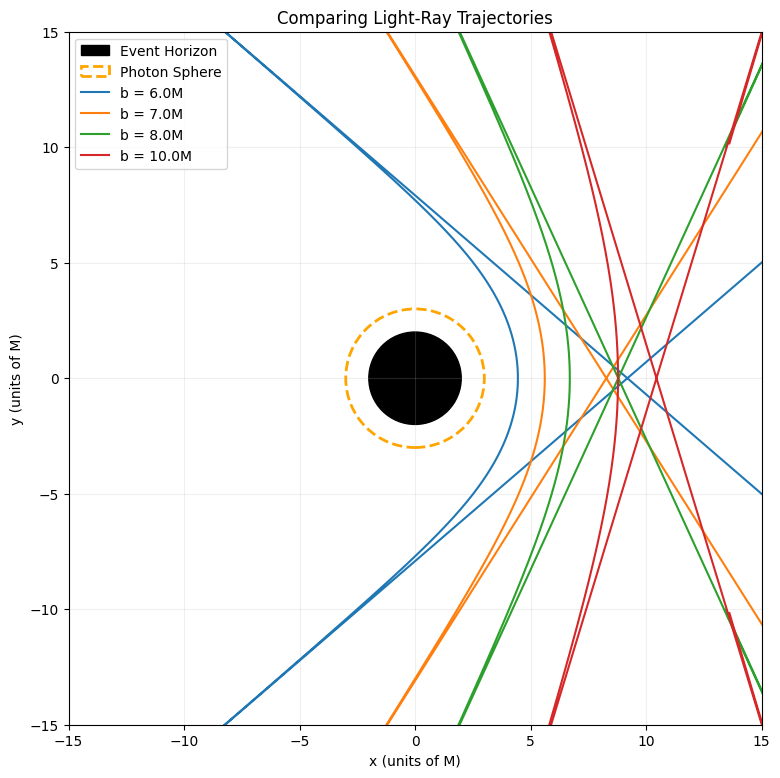

In [ ]:
# impact_parameters = [6.0, 7.0, 8.0, 10.0]

# fig, ax = plt.subplots(figsize=(9, 9))

# ax.add_patch(Circle((0, 0), r_s, color="black",
#                     label="Event Horizon"))

# ax.add_patch(Circle((0, 0), r_ph, fill=False,
#                     linestyle="--", color="orange",
#                     linewidth=2, label="Photon Sphere"))

# for b in impact_parameters:
#     angles, radii = escaped_ray(b)

#     angles_full = np.concatenate((-angles[:0:-1], angles))
#     radii_full = np.concatenate((radii[:0:-1], radii))

#     x = radii_full * np.cos(angles_full)
#     y = radii_full * np.sin(angles_full)

#     ax.plot(x, y, linewidth=1.5, label=f"b = {b}M")

# ax.set_aspect("equal")
# ax.set_xlim(-15, 15)
# ax.set_ylim(-15, 15)
# ax.set_xlabel("x (units of M)")
# ax.set_ylabel("y (units of M)")
# ax.set_title("Comparing Light-Ray Trajectories")
# ax.grid(alpha=0.2)
# ax.legend()

# plt.show()